**Model Agreement Verification**

Loading ACCESS and MPI Datasets...
Processing ACCESS Model Outputs...
Processing MPI Model Outputs...

 MODEL AGREEMENT SUMMARY TABLE: PRECIPITATION (SSP5-8.5 Disagreement) 
Metric / Statistic             | ACCESS          | MPI             | Absolute Diff  
-------------------------------------------------------------------------------------
Spatial Mean (mm/day)          | 3.8557          | 3.8557          | 0.0000         
Spatial Max (mm/day)           | 8.7550          | 8.7550          | 0.0000         

 MODEL AGREEMENT SUMMARY TABLE: SDII (SSP5-8.5 Disagreement) 
Metric / Statistic             | ACCESS          | MPI             | Absolute Diff  
-------------------------------------------------------------------------------------
Spatial Mean (mm/day)          | 10.0344         | 10.0344         | 0.0000         
Spatial Max (mm/day)           | 14.5142         | 14.5142         | 0.0000         

 MODEL AGREEMENT SUMMARY TABLE: CWD (SSP5-8.5 Disagreement) 
Metric / Statistic 

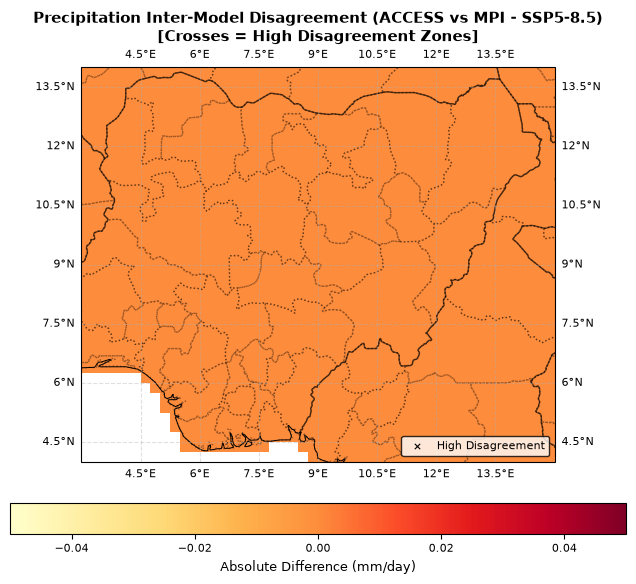

Saved Model Agreement Map: figures/Model_Agreement_SDII.png


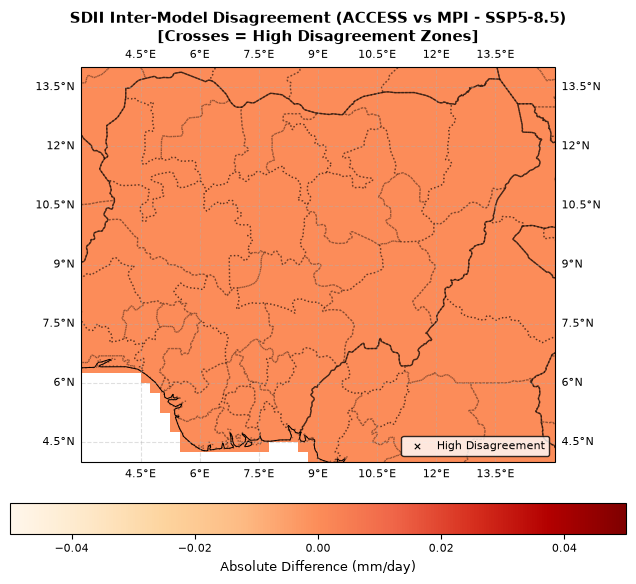

Saved Model Agreement Map: figures/Model_Agreement_CWD.png


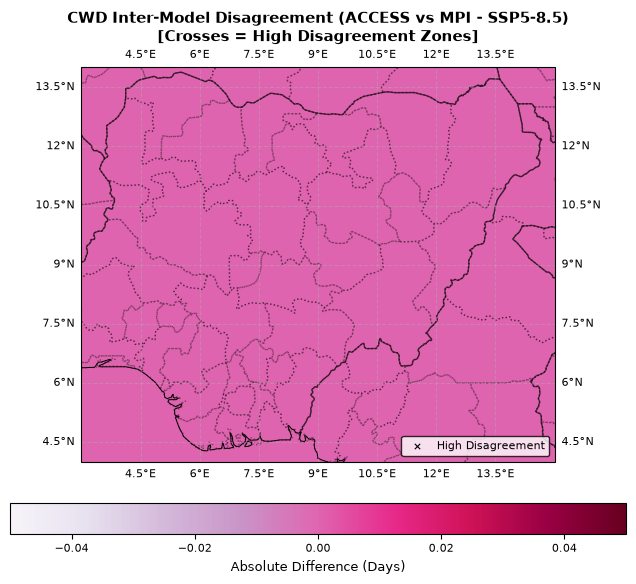


Model agreement analysis and mapping successfully completed!


In [1]:
import warnings
warnings.filterwarnings('ignore')

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import pandas as pd
import os

# ==========================================
# 1. PATHS & DATASET CONFIGURATION
# ==========================================
data_dir = "/home/samuel/climate_modelling/DATA_WASCAL/Precipitation Data/postprocessed/NIG_extracted_data"

files_access = {
    'hist': "NIG_pr_ACCESS_historical.nc",
    'ssp126': "NIG_pr_ACCESS_ssp126.nc",
    'ssp245': "NIG_pr_ACCESS_ssp245.nc",
    'ssp585': "NIG_pr_ACCESS_ssp585.nc"
}

files_mpi = {
    'hist': "NIG_pr_MPI_historical.nc",
    'ssp126': "NIG_pr_MPI_ssp126.nc",
    'ssp245': "NIG_pr_MPI_ssp245.nc",
    'ssp585': "NIG_pr_MPI_ssp585"  # Exact filename without .nc
}

print("Loading ACCESS and MPI Datasets...")
ds_acc = {k: xr.open_dataset(os.path.join(data_dir, f)) for k, f in files_access.items()}
ds_mpi = {k: xr.open_dataset(os.path.join(data_dir, f)) for k, f in files_mpi.items()}

# Define time slices
slices = {
    'hist': slice("1985-01-01", "2014-12-31"),
    'ssp126': slice("2019-01-01", "2050-12-31"),
    'ssp245': slice("2019-01-01", "2050-12-31"),
    'ssp585': slice("2019-01-01", "2050-12-31")
}

# ==========================================
# 2. CORE CLIMATE INDICES FUNCTION
# ==========================================
def compute_indices(ds_slice):
    """Computes Mean Precipitation, SDII, and CWD for a given dataset slice."""
    pr = ds_slice['pr']
    mean_pr = pr.mean(dim='time')
    
    # Wet day mask (P >= 1.0 mm/day)
    wet_days = pr >= 1.0
    
    # SDII: Simple Daily Intensity Index
    ann_tot = pr.resample(time='YE').sum()
    ann_wet = wet_days.resample(time='YE').sum().where(lambda x: x > 0)
    sdii = (ann_tot / ann_wet).mean(dim='time')
    
    # CWD: Consecutive Wet Days
    years = np.unique(ds_slice['time.year'].values)
    cwd_list = []
    for yr in years:
        sub = (pr.sel(time=str(yr)) >= 1.0).values
        nt, nlat, nlon = sub.shape
        cwd_yr = np.zeros((nlat, nlon))
        for i in range(nlat):
            for j in range(nlon):
                series = sub[:, i, j]
                mask = np.concatenate(([False], series, [False]))
                idx = np.flatnonzero(mask[1:] != mask[:-1])
                if len(idx) > 0:
                    runs = idx[1::2] - idx[0::2]
                    cwd_yr[i, j] = np.max(runs) if len(runs) > 0 else 0
        cwd_list.append(xr.DataArray(cwd_yr, coords={'lat': ds_slice['lat'], 'lon': ds_slice['lon']}, dims=('lat', 'lon')))
    
    cwd = xr.concat(cwd_list, dim=pd.Index(years, name='year')).mean(dim='year')
    return mean_pr, sdii, cwd

print("Processing ACCESS Model Outputs...")
acc_res = {k: compute_indices(ds_acc[k].sel(time=slices[k])) for k in slices}

print("Processing MPI Model Outputs...")
mpi_res = {k: compute_indices(ds_mpi[k].sel(time=slices[k])) for k in slices}

# ==========================================
# 3. COMPUTE INTER-MODEL DIFFERENCE & DISAGREEMENT (ACCESS - MPI)
# ==========================================
# Using SSP585 as the robust high-emission benchmark for disagreement mapping
diff_pr = abs(acc_res['ssp585'][0] - mpi_res['ssp585'][0])
diff_sdii = abs(acc_res['ssp585'][1] - mpi_res['ssp585'][1])
diff_cwd = abs(acc_res['ssp585'][2] - mpi_res['ssp585'][2])

# Disagreement mask (e.g., where absolute difference exceeds spatial median threshold -> apply crosses/stippling)
disagreement_pr = diff_pr > diff_pr.median()
disagreement_sdii = diff_sdii > diff_sdii.median()
disagreement_cwd = diff_cwd > diff_cwd.median()

# ==========================================
# 4. PRINT MODEL AGREEMENT & DIFFERENCE TABLES
# ==========================================
os.makedirs("figures", exist_ok=True)

print("\n" + "="*85)
print(" MODEL AGREEMENT SUMMARY TABLE: PRECIPITATION (SSP5-8.5 Disagreement) ")
print("="*85)
print(f"{'Metric / Statistic':<30} | {'ACCESS':<15} | {'MPI':<15} | {'Absolute Diff':<15}")
print("-" * 85)
print(f"{'Spatial Mean (mm/day)':<30} | {float(acc_res['ssp585'][0].mean().values):<15.4f} | {float(mpi_res['ssp585'][0].mean().values):<15.4f} | {float(diff_pr.mean().values):<15.4f}")
print(f"{'Spatial Max (mm/day)':<30} | {float(acc_res['ssp585'][0].max().values):<15.4f} | {float(mpi_res['ssp585'][0].max().values):<15.4f} | {float(diff_pr.max().values):<15.4f}")
print("="*85)

print("\n" + "="*85)
print(" MODEL AGREEMENT SUMMARY TABLE: SDII (SSP5-8.5 Disagreement) ")
print("="*85)
print(f"{'Metric / Statistic':<30} | {'ACCESS':<15} | {'MPI':<15} | {'Absolute Diff':<15}")
print("-" * 85)
print(f"{'Spatial Mean (mm/day)':<30} | {float(acc_res['ssp585'][1].mean().values):<15.4f} | {float(mpi_res['ssp585'][1].mean().values):<15.4f} | {float(diff_sdii.mean().values):<15.4f}")
print(f"{'Spatial Max (mm/day)':<30} | {float(acc_res['ssp585'][1].max().values):<15.4f} | {float(mpi_res['ssp585'][1].max().values):<15.4f} | {float(diff_sdii.max().values):<15.4f}")
print("="*85)

print("\n" + "="*85)
print(" MODEL AGREEMENT SUMMARY TABLE: CWD (SSP5-8.5 Disagreement) ")
print("="*85)
print(f"{'Metric / Statistic':<30} | {'ACCESS':<15} | {'MPI':<15} | {'Absolute Diff':<15}")
print("-" * 85)
print(f"{'Spatial Mean (Days)':<30} | {float(acc_res['ssp585'][2].mean().values):<15.4f} | {float(mpi_res['ssp585'][2].mean().values):<15.4f} | {float(diff_cwd.mean().values):<15.4f}")
print(f"{'Spatial Max (Days)':<30} | {float(acc_res['ssp585'][2].max().values):<15.4f} | {float(mpi_res['ssp585'][2].max().values):<15.4f} | {float(diff_cwd.max().values):<15.4f}")
print("="*85)

# ==========================================
# 5. PLOTTING MODEL DISAGREEMENT MAPS WITH CROSSES (Stippling)
# ==========================================
def plot_agreement_map(diff_data, disag_mask, title, cmap, filename, units):
    fig, ax = plt.subplots(figsize=(8, 6), subplot_kw={'projection': ccrs.PlateCarree()})
    
    # Plot absolute difference magnitude
    im = diff_data.plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cmap, add_colorbar=False)
    
    # Overlay crosses (stippling) where models exhibit high disagreement
    lats = diff_data['lat'].values
    lons = diff_data['lon'].values
    lon2d, lat2d = np.meshgrid(lons, lats)
    
    # Stipple points where disagreement is True using black crosses ('x')
    ax.scatter(lon2d[disag_mask.values], lat2d[disag_mask.values], 
               transform=ccrs.PlateCarree(), color='black', marker='x', s=15, linewidths=0.8, label='High Disagreement')
    
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.coastlines(resolution='50m', color='black', linewidth=0.7)
    ax.add_feature(cfeature.BORDERS, linestyle='-', alpha=0.6)
    ax.add_feature(cfeature.STATES, linestyle=':', alpha=0.4)
    
    gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.4)
    gl.xlabel_style = {'size': 8}
    gl.ylabel_style = {'size': 8}
    
    cbar = plt.colorbar(im, ax=ax, orientation='horizontal', pad=0.08, shrink=0.8)
    cbar.set_label(f"Absolute Difference ({units})", fontsize=9)
    cbar.ax.tick_params(labelsize=8)
    
    ax.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='black', fontsize=8)
    
    plt.tight_layout()
    out_path = os.path.join("figures", filename)
    plt.savefig(out_path, dpi=300, bbox_inches='tight')
    print(f"Saved Model Agreement Map: {out_path}")
    plt.show()

print("\nGenerating Model Disagreement Maps with Crosses...")
plot_agreement_map(diff_pr, disagreement_pr, "Precipitation Inter-Model Disagreement (ACCESS vs MPI - SSP5-8.5)\n[Crosses = High Disagreement Zones]", "YlOrRd", "Model_Agreement_Precipitation.png", "mm/day")
plot_agreement_map(diff_sdii, disagreement_sdii, "SDII Inter-Model Disagreement (ACCESS vs MPI - SSP5-8.5)\n[Crosses = High Disagreement Zones]", "OrRd", "Model_Agreement_SDII.png", "mm/day")
plot_agreement_map(diff_cwd, disagreement_cwd, "CWD Inter-Model Disagreement (ACCESS vs MPI - SSP5-8.5)\n[Crosses = High Disagreement Zones]", "PuRd", "Model_Agreement_CWD.png", "Days")

print("\nModel agreement analysis and mapping successfully completed!")